# Experiment 07: ID3 Decision Tree Classification

## Aim
To implement the ID3 (Iterative Dichotomiser 3) algorithm from scratch using entropy and information gain to classify examples.

## Dataset and source
- Dataset: Classic Play Tennis dataset
- Source: Custom categorical dataset included in this notebook
- Number of records: 14
- Input attributes: Outlook, Temperature, Humidity, Wind
- Target: PlayTennis (Yes/No)
- Download required: No

## Theory
ID3, developed by Ross Quinlan, selects the attribute with the highest information gain at each node and recursively creates branches for attribute values.

Entropy:
\[
H(S)=-\sum_i p_i\log_2(p_i)
\]

Information gain:
\[
IG(S,A)=H(S)-\sum_v\frac{|S_v|}{|S|}H(S_v)
\]

Classic ID3 is designed for categorical attributes. This program implements ID3 directly rather than using CART or C4.5 under another name.

## Algorithm
1. Load the categorical Play Tennis dataset.
2. Calculate target entropy.
3. Calculate information gain for each remaining attribute.
4. Select the attribute with maximum information gain.
5. Create branches for its values and recursively build subtrees.
6. Predict the training examples and a new example.
7. Plot root-level information gain.


## Program

Experiment: ID3 Decision Tree
Dataset source: Classic Play Tennis dataset (custom categorical data)
Number of records: 14
 Outlook Temperature Humidity   Wind PlayTennis
   Sunny         Hot     High   Weak         No
   Sunny         Hot     High Strong         No
Overcast         Hot     High   Weak        Yes
    Rain        Mild     High   Weak        Yes
    Rain        Cool   Normal   Weak        Yes
    Rain        Cool   Normal Strong         No
Overcast        Cool   Normal Strong        Yes
   Sunny        Mild     High   Weak         No
   Sunny        Cool   Normal   Weak        Yes
    Rain        Mild   Normal   Weak        Yes
   Sunny        Mild   Normal Strong        Yes
Overcast        Mild     High Strong        Yes
Overcast         Hot   Normal   Weak        Yes
    Rain        Mild     High Strong         No
\nTarget distribution:
PlayTennis
Yes    9
No     5
Name: count, dtype: int64
\nInformation Gain at Root:
Outlook: 0.2467
Humidity: 0.1518
Wind: 0.0481
Temper

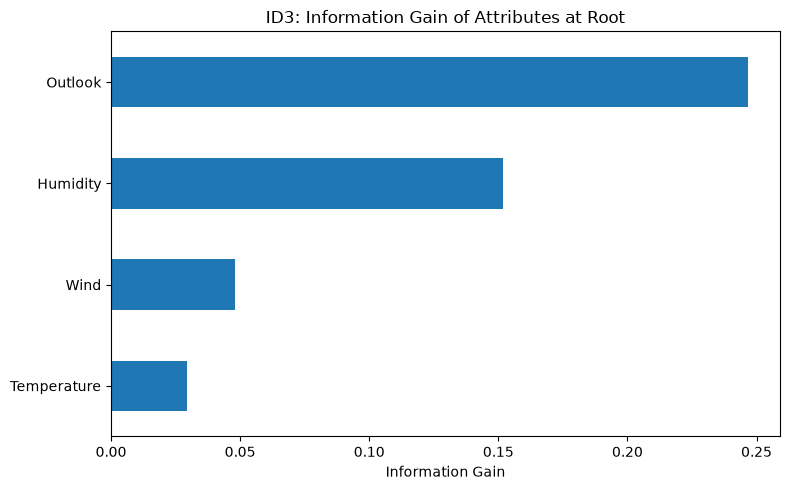

\nNew example: {'Outlook': 'Sunny', 'Temperature': 'Cool', 'Humidity': 'High', 'Wind': 'Strong'}
Predicted PlayTennis: No


In [1]:
import math
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

# Classic categorical Play Tennis dataset (14 examples)
data = [
["Sunny","Hot","High","Weak","No"],
["Sunny","Hot","High","Strong","No"],
["Overcast","Hot","High","Weak","Yes"],
["Rain","Mild","High","Weak","Yes"],
["Rain","Cool","Normal","Weak","Yes"],
["Rain","Cool","Normal","Strong","No"],
["Overcast","Cool","Normal","Strong","Yes"],
["Sunny","Mild","High","Weak","No"],
["Sunny","Cool","Normal","Weak","Yes"],
["Rain","Mild","Normal","Weak","Yes"],
["Sunny","Mild","Normal","Strong","Yes"],
["Overcast","Mild","High","Strong","Yes"],
["Overcast","Hot","Normal","Weak","Yes"],
["Rain","Mild","High","Strong","No"]
]
columns = ["Outlook", "Temperature", "Humidity", "Wind", "PlayTennis"]
df = pd.DataFrame(data, columns=columns)
target = "PlayTennis"
attributes = columns[:-1]

print("Experiment: ID3 Decision Tree")
print("Dataset source: Classic Play Tennis dataset (custom categorical data)")
print("Number of records:", len(df))
print(df.to_string(index=False))
print("\\nTarget distribution:")
print(df[target].value_counts())

def entropy(labels):
    counts = Counter(labels)
    total = len(labels)
    return -sum((n / total) * math.log2(n / total)
                for n in counts.values() if n > 0)

def information_gain(frame, attribute):
    parent_entropy = entropy(frame[target])
    weighted_entropy = 0.0
    for _, subset in frame.groupby(attribute):
        weighted_entropy += len(subset) / len(frame) * entropy(subset[target])
    return parent_entropy - weighted_entropy

def build_id3(frame, attrs):
    labels = frame[target]
    if labels.nunique() == 1:
        return labels.iloc[0]
    if not attrs:
        return labels.mode().iloc[0]

    gains = {a: information_gain(frame, a) for a in attrs}
    best = max(gains, key=gains.get)
    node = {best: {"__majority__": labels.mode().iloc[0]}}
    remaining = [a for a in attrs if a != best]

    for value in frame[best].unique():
        subset = frame[frame[best] == value]
        node[best][value] = (
            build_id3(subset, remaining) if len(subset)
            else labels.mode().iloc[0]
        )
    return node

def predict(tree, sample):
    if not isinstance(tree, dict):
        return tree
    attribute = next(iter(tree))
    branches = tree[attribute]
    value = sample.get(attribute)
    if value not in branches:
        return branches["__majority__"]
    return predict(branches[value], sample)

def print_tree(tree, indent=""):
    if not isinstance(tree, dict):
        print(indent + "-> " + str(tree))
        return
    attribute = next(iter(tree))
    print(indent + "[" + attribute + "]")
    for value, subtree in tree[attribute].items():
        if value == "__majority__":
            continue
        print(indent + "  " + str(value) + ":")
        print_tree(subtree, indent + "    ")

print("\\nInformation Gain at Root:")
gains = {a: information_gain(df, a) for a in attributes}
for attribute, gain in sorted(gains.items(), key=lambda item: item[1], reverse=True):
    print(f"{attribute}: {gain:.4f}")

tree = build_id3(df, attributes)
print("\\nLearned ID3 Decision Tree:")
print_tree(tree)

actual = df[target].tolist()
predicted = [predict(tree, row[attributes].to_dict())
             for _, row in df.iterrows()]
accuracy = sum(a == p for a, p in zip(actual, predicted)) / len(actual)

print("\\nPredictions on training examples:")
print("Actual labels:   ", actual)
print("Predicted labels:", predicted)
print(f"Training accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")

pd.Series(gains).sort_values().plot(kind="barh", figsize=(8, 5))
plt.xlabel("Information Gain")
plt.title("ID3: Information Gain of Attributes at Root")
plt.tight_layout()
plt.show()

new_example = {
    "Outlook": "Sunny", "Temperature": "Cool",
    "Humidity": "High", "Wind": "Strong"
}
print("\\nNew example:", new_example)
print("Predicted PlayTennis:", predict(tree, new_example))


## Expected output
The program prints the dataset, target distribution, information gain for each root attribute, the learned tree, predictions, training accuracy, and a prediction for a new example. It also plots information gain.

The dataset is small and intended to demonstrate ID3. Accuracy measured on the training examples is not an unbiased estimate of performance on unseen data.

## Result
The ID3 decision tree was implemented from scratch using entropy and information gain. The learned tree was used to classify the Play Tennis examples and predict a new categorical example.

## Viva-voce questions and answers

**1. What is ID3?** ID3 stands for Iterative Dichotomiser 3 and selects attributes using information gain.

**2. Who developed ID3?** Ross Quinlan.

**3. Which measure does ID3 use?** Information gain.

**4. What is entropy?** A measure of impurity or uncertainty in the target labels.

**5. What is information gain?** The reduction in entropy after splitting on an attribute.

**6. How does ID3 build a tree?** It selects the highest-information-gain attribute and recursively splits each subset.

**7. Can classic ID3 handle continuous attributes directly?** Not in its original form; continuous features usually need discretization or an extension.

**8. What is a leaf node?** A terminal node that returns the predicted class.

**9. How does ID3 differ from C4.5?** ID3 uses information gain; C4.5 uses gain ratio and adds support for continuous attributes and pruning.

**10. How does ID3 differ from CART?** ID3 uses information gain for categorical splits; CART builds binary splits and commonly uses Gini impurity.

**11. What happens if no attributes remain?** The majority class is returned.

**12. Why use Play Tennis?** It is a small categorical dataset that clearly demonstrates entropy and information gain.
